# P8.14 — Protótipo analógico Chebyshev-I passa-baixas (forma racional)

**Referência:** Ingle & Proakis, *DSP Using MATLAB*, 3ª ed., p. 465 · DTA §2.2 (item 11), §3.2.B e §4 (Resolução P8.14).

> *Design a lowpass analog Chebyshev-I filter with an acceptable ripple of 1 dB for |Ω| ≤ 10 and an attenuation of 50 dB or greater beyond |Ω| = 15 rad/sec. Determine the system function in a rational function form. Plot the magnitude response, the log-magnitude response in dB, the group-delay, and the impulse response of the filter.*

| Parâmetro | Valor |
|---|---|
| Passagem | $|\Omega| \le \Omega_p = 10$ rad/s, $R_p = 1$ dB |
| Rejeição | $|\Omega| \ge \Omega_s = 15$ rad/s, $A_s = 50$ dB |
| Forma pedida | racional |

In [1]:
# Configuração do ambiente (local ou Google Colab)
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # No Colab, disponibilize o projeto em PROJECT_DIR antes de executar:
    #   (a) Arquivos → upload de dsp-avaliacao-2.zip e  !unzip -q dsp-avaliacao-2.zip
    #   (b) ou monte o Drive:  from google.colab import drive; drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/dsp-avaliacao-2")
    %pip install -q -r {PROJECT_DIR}/requirements.txt
else:
    PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

for p in (PROJECT_DIR, PROJECT_DIR / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print("Projeto em:", PROJECT_DIR)

Projeto em: /mnt/storage/projects/dsp-avaliacao-2


## 1. Método

O Chebyshev-I distribui o erro **igualmente** (equiripple) na passagem:

$$|H_a(j\Omega)|^2 = \frac{1}{1 + \epsilon^2 T_N^2(\Omega/\Omega_p)}$$

$T_N$ é o polinômio de Chebyshev de ordem $N$. Ele oscila entre ±1 para $|x| \le 1$ e cresce como $\cosh(N\cosh^{-1}x)$ fora desse intervalo.

**Ondulação:** $\epsilon = \sqrt{10^{R_p/10} - 1} = \sqrt{10^{0.1} - 1} = 0.508847$.

**Ordem.** Impondo $A_s$ em $\Omega_s$ e usando $T_N(x) = \cosh(N\cosh^{-1}x)$:

$$g = \frac{\sqrt{10^{A_s/10}-1}}{\epsilon} = 621.46, \qquad N = \left\lceil \frac{\cosh^{-1} g}{\cosh^{-1}(\Omega_s/\Omega_p)} \right\rceil = \left\lceil \frac{7.125}{0.9624} \right\rceil = \lceil 7.40 \rceil = 8$$

**Polos** sobre uma elipse:

$$\alpha = \tfrac{1}{\epsilon} + \sqrt{1 + \tfrac{1}{\epsilon^2}},\quad a = \tfrac12(\alpha^{1/N} - \alpha^{-1/N}),\quad b = \tfrac12(\alpha^{1/N} + \alpha^{-1/N})$$

$$p_k = -a\,\Omega_p\sin\frac{(2k+1)\pi}{2N} + j\,b\,\Omega_p\cos\frac{(2k+1)\pi}{2N}$$

**Ganho.** Com $N$ par, $T_N(0) = \pm1$, então $|H_a(0)| = 1/\sqrt{1+\epsilon^2}$: o DC fica num **vale** da ondulação. Isso implica $B = a_0/\sqrt{1+\epsilon^2}$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Math, display

from dsp_av2.iir import analysis, forms
from dsp_av2.specs import P8_14 as SPEC
from exercises import p8_14

proto = p8_14.design()
print(f"ε = {proto.params['epsilon']:.6f}")
print(f"N = {proto.N}  (antes do teto: {proto.params['N_real']:.4f})")
print(f"H(0) = 1/√(1+ε²) = {proto.params['dc_gain']:.6f}  ({20 * np.log10(proto.params['dc_gain']):.4f} dB)\n")
print("Polos:")
for p in sorted(proto.p, key=lambda q: q.imag):
    print(f"  {p.real:9.5f} {p.imag:+9.5f}j")

ε = 0.508847
N = 8  (antes do teto: 7.4034)
H(0) = 1/√(1+ε²) = 0.891251  (-1.0000 dB)

Polos:
   -0.35008  -9.96451j
   -0.99695  -8.44751j
   -1.49204  -5.64444j
   -1.75998  -1.98206j
   -1.75998  +1.98206j
   -1.49204  +5.64444j
   -0.99695  +8.44751j
   -0.35008  +9.96451j


## 2. Função de sistema na forma racional

In [3]:
b, a = p8_14.rational_form(proto)
display(Math(r"H_a(s) = \dfrac{" + forms.poly_to_latex(b) + "}{" + forms.poly_to_latex(a) + "}"))
print(f"B / a0 = {b[0] / a[-1]:.6f}  (= 1/√(1+ε²) = {1 / np.sqrt(1 + proto.params['epsilon'] ** 2):.6f})")

<IPython.core.display.Math object>

B / a0 = 0.891251  (= 1/√(1+ε²) = 0.891251)


## 3. Gráficos pedidos

Magnitude, log-magnitude, atraso de grupo (analítico, a partir dos polos) e resposta ao impulso.

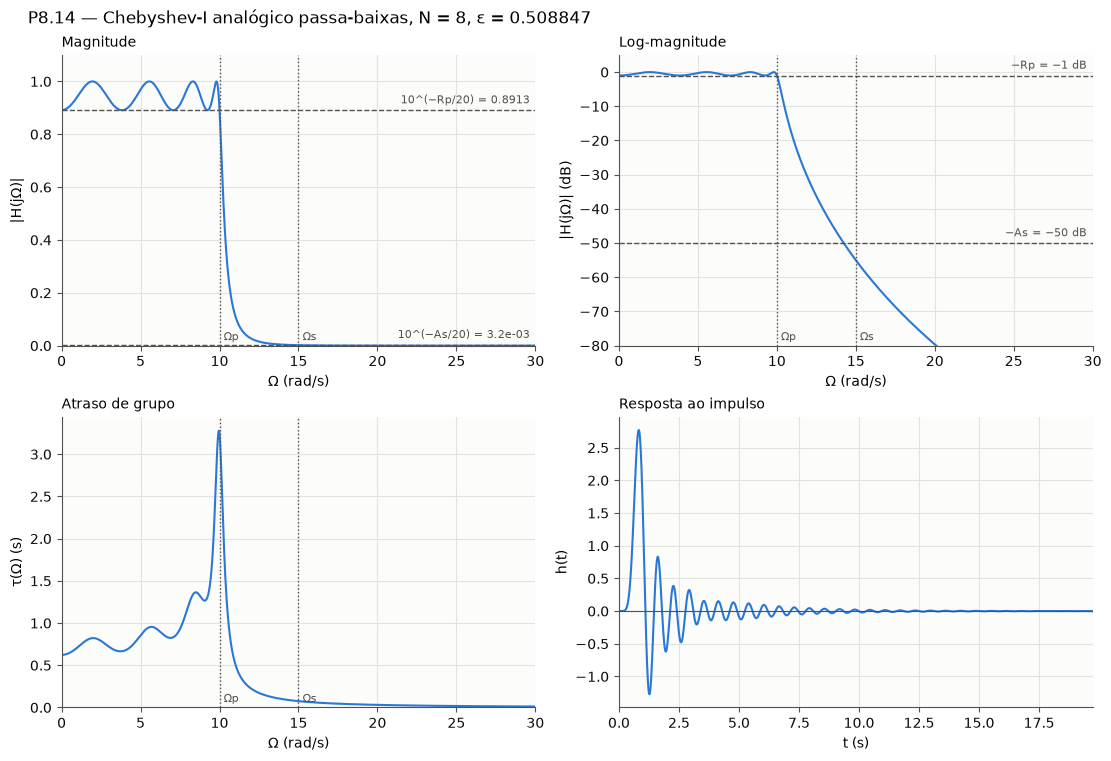

In [4]:
fig = p8_14.plot(proto)
plt.show()

**Leitura dos gráficos:**

- **Magnitude:** 9 extremos em $[0, \Omega_p]$ ($N + 1$), alternando entre 1 e $10^{-1/20} = 0.891$. Em DC, o valor é 0.891 (vale), porque $N$ é par.
- **Atraso de grupo:** muito maior e mais irregular que no Butterworth, com pico de ≈ 3.3 s em $\Omega_p$. Os polos do Chebyshev ficam muito mais perto do eixo $j\Omega$ ($a \ll b$, elipse achatada). Esse é o preço da transição mais abrupta.
- **Resposta ao impulso:** oscilação longa e pouco amortecida perto de $\Omega_p$ (período ≈ $2\pi/10 \approx 0.63$ s), consequência dos mesmos polos de baixo amortecimento.

## 4. Validação contra a especificação

In [5]:
print(p8_14.validate(proto))

from scipy import signal
z_sp, p_sp, k_sp = signal.cheby1(proto.N, SPEC.rp_db, SPEC.wp, analog=True, output="zpk")
print("\nmax |p − p_scipy| =", np.max(np.abs(np.sort_complex(proto.p) - np.sort_complex(p_sp))))
print("k / k_scipy − 1   =", proto.k / k_sp - 1)

Validação P8.14
  [OK  ] Perda máx. na passagem [dB]: 1.0000 <= 1.0000  (folga +0.0000)
  [OK  ] Atenuação mín. na rejeição [dB]: 54.9872 >= 50.0000  (folga +4.9872)
  [OK  ] Atenuação em Ωs com N−1 = 7 [dB] (deve falhar): 46.6278 <= 50.0000  (folga +3.3722)
  Resultado: ATENDE à especificação

max |p − p_scipy| = 1.8452761694870047e-15
k / k_scipy − 1   = 6.661338147750939e-16


In [6]:
from dsp_av2.iir.prototypes import butter_order
N_b, N_b_real = butter_order(SPEC.wp, SPEC.ws, SPEC.rp_db, SPEC.as_db)
print(f"Butterworth com as mesmas especificações: N = ⌈{N_b_real:.2f}⌉ = {N_b}   |   Chebyshev-I: N = {proto.N}")

Butterworth com as mesmas especificações: N = ⌈15.86⌉ = 16   |   Chebyshev-I: N = 8


## 5. Conclusão

- $\epsilon = 0.508847$ e $N = 8$ ($\lceil 7.40 \rceil$). $B = 1.535333\times10^6$ e $a_0 = 1.722672\times10^6$ coincidem com o DTA.
- A perda é exatamente 1 dB em $\Omega_p = 10$ rad/s (equiripple) e a atenuação é ≈ 54.99 dB em $\Omega_s = 15$ rad/s. Com $N = 7$ seriam só 46.6 dB, o que confirma que 8 é a ordem mínima.
- Comparação com o Butterworth: com as mesmas especificações ($\Omega_s/\Omega_p = 1.5$), um Butterworth precisaria de $N = \lceil 15.86 \rceil = 16$ (calculado na célula abaixo). A ondulação na passagem reduz a ordem pela metade, ao custo de um atraso de grupo muito irregular.